In [1]:
import numpy as np
from scipy.linalg import svd

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy  as sp

# from scipy.linalg import fractional_matrix_power
# import sys
# sys.path.append('./utils')

# import h5py
import importlib
# import analysis
# import datasets as ds
import seaborn as sns

# %matplotlib ipympl
# %matplotlib inline
from deeptime.decomposition import VAMP, EDMD, DMD, KernelCCA, KernelEDMD
from deeptime.clustering import KMeans
from deeptime.decomposition import vamp_score_cv
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post104+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor)) + 0.01
    # print(clean)

    x = 0
    a_decay = 0.7
    a_rise = 5

    (0.01 / 5) * (5 / 0.01) * 5

    b = 0

    n_rise = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(bool))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[c_ix][i]:
                a = a_rise
                n_rise = 5
            elif n_rise > 0:
                if clean[c_ix, i - 1] > 1:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2])# + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [5]:
n_components = 1

In [6]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=250,
    n_components=n_components,
    noise=0.01,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=2,
    firing_prop=0.05,
)

In [7]:
X.shape

(1, 500)

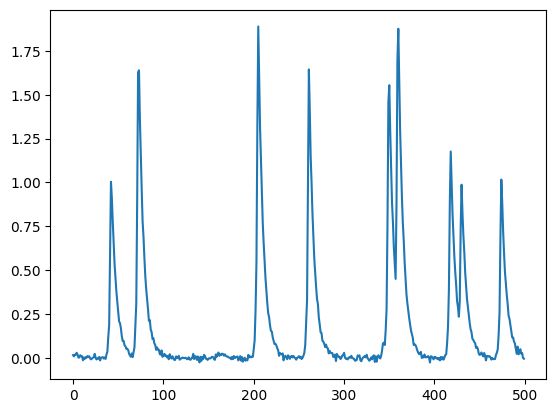

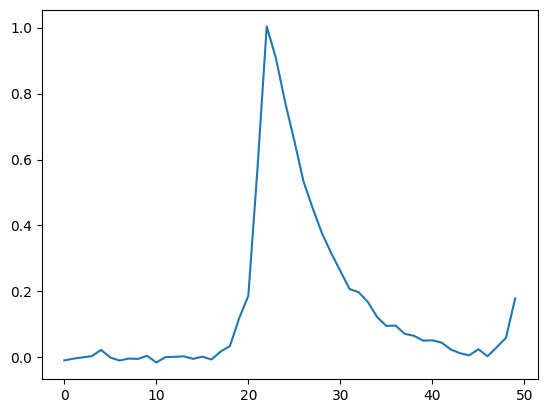

In [8]:
plt.plot(X[0])
# plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[20:70])

In [9]:
from scipy import linalg

In [10]:
from deeptime.numeric import spd_inv_sqrt, spd_inv_split

In [11]:
from deeptime.basis import Monomials

In [13]:
X_ = X - X.mean()

<Axes: >

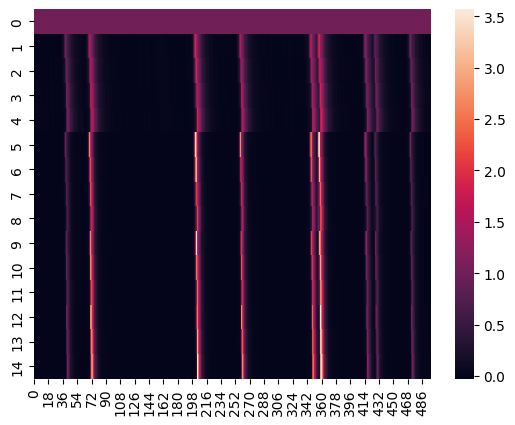

In [20]:
lag = 4
H = np.flipud(sp.linalg.hankel(X.T[:lag], X.T[lag-1:]))

monomials = Monomials(p=2, d=4)
M = monomials.transform(H.T).T

sns.heatmap(M)

In [21]:
M.shape

(15, 497)

In [22]:
cov = (M @ M.T) / M.shape[1]

<Axes: >

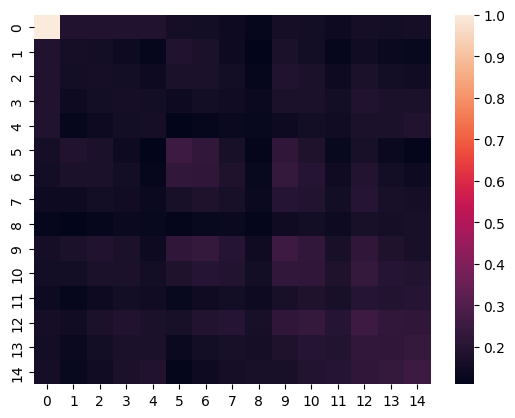

In [23]:
sns.heatmap(cov)

In [24]:
cov

array([[1.        , 0.18698363, 0.18703014, 0.18704776, 0.18702379,
        0.16208934, 0.15450428, 0.13824116, 0.12123013, 0.16208991,
        0.15450457, 0.138242  , 0.16209005, 0.15450485, 0.16208903],
       [0.18698363, 0.16208934, 0.15450428, 0.13824116, 0.12123013,
        0.18936973, 0.17389078, 0.14074416, 0.10993995, 0.17596803,
        0.15357602, 0.12243981, 0.15115748, 0.13093758, 0.12841858],
       [0.18703014, 0.15450428, 0.16208991, 0.15450457, 0.138242  ,
        0.17389078, 0.17596803, 0.15357602, 0.12243981, 0.18936974,
        0.17389078, 0.14074417, 0.17596803, 0.15357602, 0.1511575 ],
       [0.18704776, 0.13824116, 0.15450457, 0.16209005, 0.15450485,
        0.14074416, 0.15357602, 0.15115748, 0.13093758, 0.17389078,
        0.17596803, 0.15357602, 0.18936974, 0.17389079, 0.17596804],
       [0.18702379, 0.12123013, 0.138242  , 0.15450485, 0.16208903,
        0.10993995, 0.12243981, 0.13093758, 0.12841858, 0.14074417,
        0.15357602, 0.1511575 , 0.17389079, 

In [26]:
n = 8

PP = cov[:n, :n]
FF = cov[n:, n:]
PF = cov[n:, :n]

In [27]:
L0 = spd_inv_sqrt(PP)
Lt = spd_inv_sqrt(FF)

K_bar_linear = L0 @ PF @ Lt

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 7 is different from 8)

In [28]:
K_bar_linear

NameError: name 'K_bar_linear' is not defined

In [222]:
import scipy

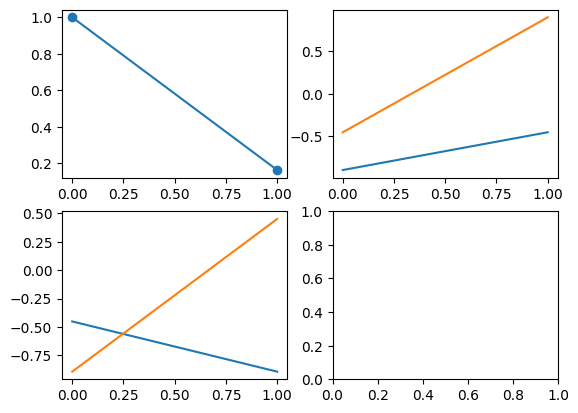

In [229]:
u, s, vt = scipy.linalg.svd(K_bar_linear, compute_uv=True, lapack_driver="gesvd")

# u = np.dot(L0, u)
# vt = np.dot(Lt, vt.T)

fig, ax = plt.subplots(2,2)
ax[0,0].plot(s / s.max(),'o-')
ax[0,1].plot(u)
ax[1,0].plot(vt.T)

In [230]:
H_past = H[2:]

In [231]:
u.shape

(2, 2)

In [232]:
projection_u = H_past.T @ u
projection_v = H_past.T @ vt

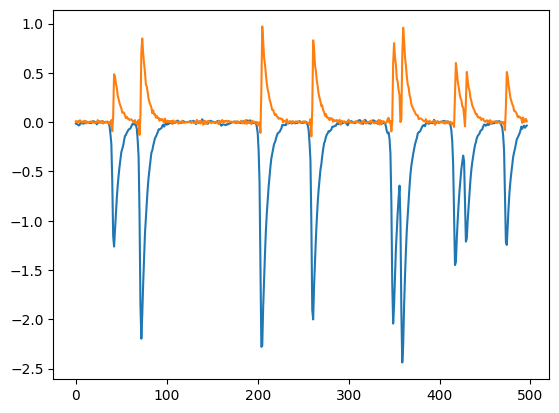

In [233]:
plt.plot(projection_u)

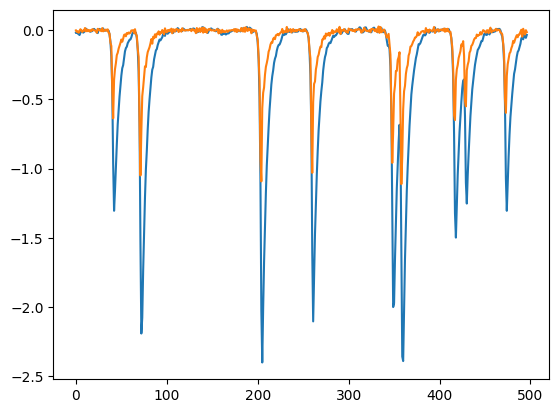

In [234]:
plt.plot(projection_v)